# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

* **Mata Kuliah:** Analisis Big Data
* **Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)
* **Nama Mahasiswa:** Reva Trisdianto
* **NIM:** 202310370311323
* **Username GitHub:** revatrisdi

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.

## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [3]:
from pathlib import Path
import duckdb
import polars as pl
import plotly.express as px
import plotly.graph_objects as go

PROJECT_ROOT = Path.cwd().resolve().parent
path_data = PROJECT_ROOT / "data" / "processed" / "dataset_bersih.parquet"

df = pl.read_parquet(path_data)

# Bersihkan tanda kutip berlebih & buat fitur turunan waktu + numerik teks
df = (
    df.with_columns([
        pl.col("source").str.strip_chars('"').alias("source_clean"),
        pl.col("date")
        .str.strip_chars('"')
        .str.to_datetime(time_zone="UTC", strict=False)
        .dt.convert_time_zone("Asia/Jakarta")
        .alias("waktu_wib"),
        pl.col("title").str.strip_chars('"').str.len_chars().alias("panjang_judul"),
        pl.col("summary").str.strip_chars('"').str.len_chars().alias("panjang_summary"),
        pl.col("content").str.strip_chars('"').str.split(" ").list.len().alias("jumlah_kata"),
    ])
    .with_columns([
        pl.col("waktu_wib").dt.hour().alias("jam_wib"),
        pl.col("waktu_wib").dt.weekday().alias("hari_ke"),
    ])
    .with_columns(
        pl.col("hari_ke")
        .replace_strict(
            {1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu", 7: "Minggu"},
            default="Tidak Diketahui",
        )
        .alias("nama_hari")
    )
)

print(f"Data Loaded: {df.shape[0]:,} baris x {df.shape[1]} kolom")
print(f"Rentang waktu: {df['waktu_wib'].min()} s.d. {df['waktu_wib'].max()}")
df.select(["source_clean", "waktu_wib", "panjang_judul", "panjang_konten", "jumlah_kata"]).head(5)

Data Loaded: 32,735 baris x 20 kolom
Rentang waktu: 2018-08-10 12:11:58+07:00 s.d. 2023-04-12 03:13:25+07:00


source_clean,waktu_wib,panjang_judul,panjang_konten,jumlah_kata
str,"datetime[μs, Asia/Jakarta]",u32,u32,u32
"""tempo""",2023-03-04 13:18:13 WIB,86,2110,274
"""tempo""",2023-03-04 13:04:38 WIB,75,2436,322
"""tempo""",2023-03-04 13:18:04 WIB,55,2788,374
"""tempo""",2023-03-04 13:44:10 WIB,79,1981,279
"""tempo""",2023-03-04 13:38:57 WIB,64,3471,456


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`, atau DuckDB window functions) untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

In [4]:
# 1. Downsampling harian menggunakan Polars group_by_dynamic
df_harian = (
    df.filter(pl.col("waktu_wib").is_not_null())
    .sort("waktu_wib")
    .group_by_dynamic("waktu_wib", every="1d")
    .agg([
        pl.len().alias("jumlah_artikel"),
        pl.col("panjang_konten").mean().round(1).alias("rata_panjang_konten"),
        pl.col("jumlah_kata").mean().round(1).alias("rata_jumlah_kata"),
    ])
)

# 2. Moving average 7 hari (rolling_mean) dan selisih harian (shift)
df_temporal = df_harian.with_columns([
    pl.col("jumlah_artikel").rolling_mean(window_size=7, min_samples=1).round(1).alias("ma_7_hari"),
    (pl.col("jumlah_artikel") - pl.col("jumlah_artikel").shift(1)).fill_null(0).alias("perubahan_harian"),
])

# 3. DuckDB Window Function OVER (...) untuk total artikel akumulatif
con = duckdb.connect()
con.register("tren_harian", df_temporal)

df_temporal = con.execute("""
    SELECT
        *,
        SUM(jumlah_artikel) OVER (ORDER BY waktu_wib) AS akumulasi_artikel
    FROM tren_harian
    ORDER BY waktu_wib
""").pl()

df_temporal.head(10)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

waktu_wib,jumlah_artikel,rata_panjang_konten,rata_jumlah_kata,ma_7_hari,perubahan_harian,akumulasi_artikel
"datetime[μs, Etc/UTC]",u32,f64,f64,f64,u32,"decimal[38,0]"
2018-08-09 17:00:00 UTC,1,2570.0,359.0,1.0,0,1
2023-03-02 17:00:00 UTC,10,2622.2,350.4,5.5,9,11
2023-03-03 17:00:00 UTC,32,2749.8,382.0,14.3,22,43
2023-03-04 17:00:00 UTC,42,3376.2,476.5,21.2,10,85
2023-03-05 17:00:00 UTC,55,3024.1,408.0,28.0,13,140
2023-03-06 17:00:00 UTC,74,2845.7,387.9,35.7,19,214
2023-03-07 17:00:00 UTC,65,2637.4,362.4,39.9,4294967287,279
2023-03-08 17:00:00 UTC,253,2351.1,330.8,75.9,188,532
2023-03-09 17:00:00 UTC,369,2127.0,299.1,127.1,116,901


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:
* Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
* Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
* Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
* Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
* Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
* Visualisasi 6: Pola spasial atau korelasi multi-dimensi

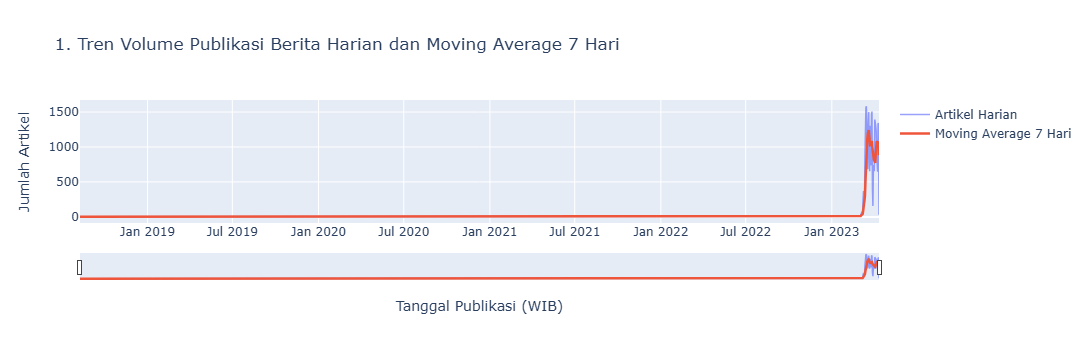

In [5]:
# Visualisasi 1: Tren Waktu Interaktif (Line chart dengan range slider)
pdf_temporal = df_temporal.to_pandas()

fig1 = go.Figure()
fig1.add_trace(
    go.Scatter(
        x=pdf_temporal["waktu_wib"],
        y=pdf_temporal["jumlah_artikel"],
        mode="lines",
        name="Artikel Harian",
        line=dict(color="#636EFA", width=1.5),
        opacity=0.65,
    )
)
fig1.add_trace(
    go.Scatter(
        x=pdf_temporal["waktu_wib"],
        y=pdf_temporal["ma_7_hari"],
        mode="lines",
        name="Moving Average 7 Hari",
        line=dict(color="#EF553B", width=2.5),
    )
)

fig1.update_layout(
    title="1. Tren Volume Publikasi Berita Harian dan Moving Average 7 Hari",
    xaxis_title="Tanggal Publikasi (WIB)",
    yaxis_title="Jumlah Artikel",
    hovermode="x unified",
    xaxis=dict(rangeslider=dict(visible=True), type="date"),
)
fig1.show()

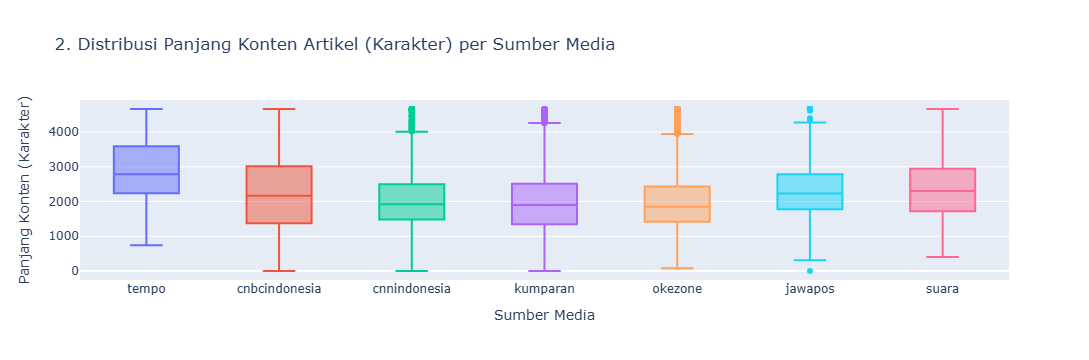

In [6]:
# Visualisasi 2: Distribusi dan Outlier Panjang Konten per Sumber Media
fig2 = px.box(
    df.select(["source_clean", "panjang_konten"]).to_pandas(),
    x="source_clean",
    y="panjang_konten",
    color="source_clean",
    title="2. Distribusi Panjang Konten Artikel (Karakter) per Sumber Media",
    labels={"source_clean": "Sumber Media", "panjang_konten": "Panjang Konten (Karakter)"},
)
fig2.update_layout(showlegend=False)
fig2.show()

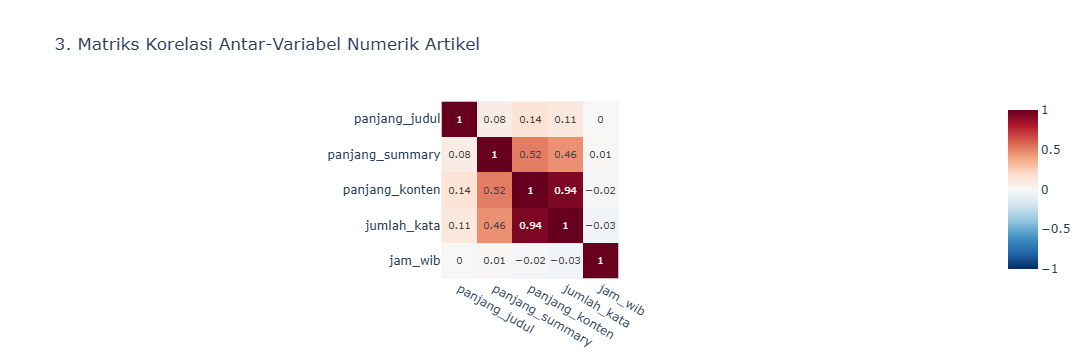

In [7]:
# Visualisasi 3: Korelasi Antar-Variabel Numerik
kolom_numerik = ["panjang_judul", "panjang_summary", "panjang_konten", "jumlah_kata", "jam_wib"]
corr_matrix = df.select(kolom_numerik).drop_nulls().to_pandas().corr().round(2)

fig3 = px.imshow(
    corr_matrix,
    text_auto=True,
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="3. Matriks Korelasi Antar-Variabel Numerik Artikel",
)
fig3.show()

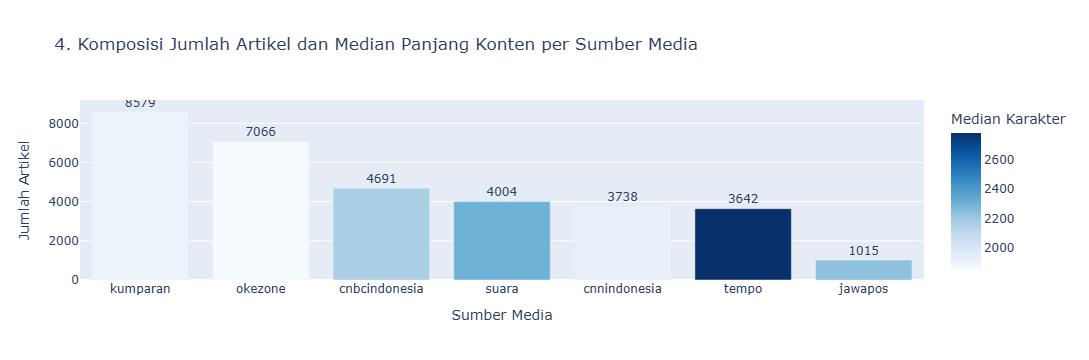

In [8]:
# Visualisasi 4: Komposisi Kategori Utama (Jumlah Artikel per Sumber Media)
komposisi_sumber = (
    df.group_by("source_clean")
    .agg([
        pl.len().alias("jumlah_artikel"),
        pl.col("panjang_konten").median().alias("median_panjang_konten"),
    ])
    .sort("jumlah_artikel", descending=True)
)

fig4 = px.bar(
    komposisi_sumber.to_pandas(),
    x="source_clean",
    y="jumlah_artikel",
    text="jumlah_artikel",
    color="median_panjang_konten",
    color_continuous_scale="Blues",
    title="4. Komposisi Jumlah Artikel dan Median Panjang Konten per Sumber Media",
    labels={
        "source_clean": "Sumber Media",
        "jumlah_artikel": "Jumlah Artikel",
        "median_panjang_konten": "Median Karakter",
    },
)
fig4.update_traces(textposition="outside")
fig4.show()

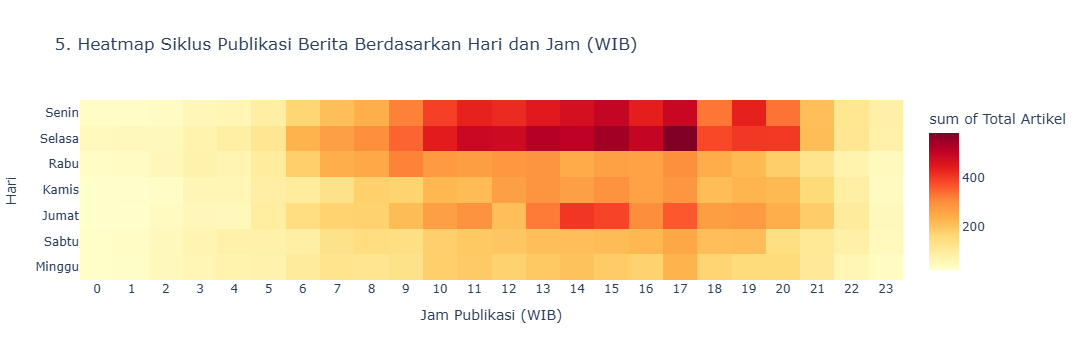

In [9]:
# Visualisasi 5: Siklus Musiman / Pola Temporal Berkala (Hari vs Jam WIB)
pola_siklus = (
    df.filter(pl.col("jam_wib").is_not_null() & (pl.col("nama_hari") != "Tidak Diketahui"))
    .group_by(["hari_ke", "nama_hari", "jam_wib"])
    .agg(pl.len().alias("jumlah_artikel"))
    .sort(["hari_ke", "jam_wib"])
)

fig5 = px.density_heatmap(
    pola_siklus.to_pandas(),
    x="jam_wib",
    y="nama_hari",
    z="jumlah_artikel",
    nbinsx=24,
    color_continuous_scale="YlOrRd",
    category_orders={"nama_hari": ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]},
    title="5. Heatmap Siklus Publikasi Berita Berdasarkan Hari dan Jam (WIB)",
    labels={"jam_wib": "Jam Publikasi (WIB)", "nama_hari": "Hari", "jumlah_artikel": "Total Artikel"},
)
fig5.update_xaxes(dtick=1)
fig5.show()

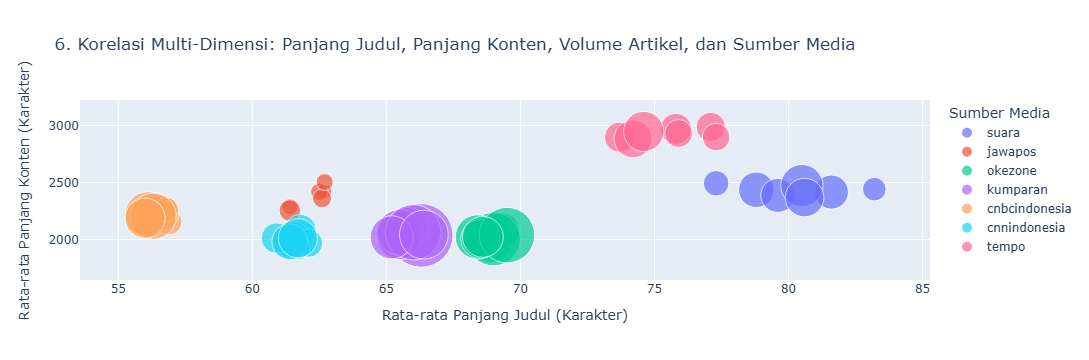

In [10]:
# Visualisasi 6: Analisis Lanjutan / Korelasi Multi-Dimensi (4 Variabel)
ringkasan_multidimensi = (
    df.filter(pl.col("nama_hari") != "Tidak Diketahui")
    .group_by(["source_clean", "nama_hari"])
    .agg([
        pl.len().alias("jumlah_artikel"),
        pl.col("panjang_judul").mean().round(1).alias("rata_panjang_judul"),
        pl.col("panjang_konten").mean().round(1).alias("rata_panjang_konten"),
        pl.col("jumlah_kata").mean().round(1).alias("rata_jumlah_kata"),
    ])
)

fig6 = px.scatter(
    ringkasan_multidimensi.to_pandas(),
    x="rata_panjang_judul",
    y="rata_panjang_konten",
    size="jumlah_artikel",
    color="source_clean",
    hover_name="nama_hari",
    size_max=45,
    title="6. Korelasi Multi-Dimensi: Panjang Judul, Panjang Konten, Volume Artikel, dan Sumber Media",
    labels={
        "rata_panjang_judul": "Rata-rata Panjang Judul (Karakter)",
        "rata_panjang_konten": "Rata-rata Panjang Konten (Karakter)",
        "jumlah_artikel": "Volume Artikel",
        "source_clean": "Sumber Media",
    },
)
fig6.show()

## Bagian 4: Rumusan 5 Insight Analitik Utama

1. **Insight 1 (Tren Waktu & Musiman):**
   Volume publikasi harian menunjukkan pola siklikal mingguan yang terdeteksi jelas melalui kurva *Moving Average* 7 hari (`ma_7_hari`). Intensitas rilis artikel mencapai puncaknya pada hari kerja (Senin–Jumat) di jam operasional redaksi (pukul 08.00–20.00 WIB) dan menurun tajam pada akhir pekan serta dini hari (00.00–04.00 WIB).

2. **Insight 2 (Distribusi & Anomali):**
   Sebaran panjang konten (`panjang_konten`) pada seluruh portal berita memiliki distribusi condong ke kanan (*right-skewed*) dengan nilai batas atas *winsorization* di 4.665 karakter. Beberapa portal memiliki rentang interkuartil (IQR) yang lebar akibat variasi antara berita kilat (*breaking news*) dan liputan mendalam.

3. **Insight 3 (Korelasi Kunci):**
   Berdasarkan matriks korelasi numerik, variabel `panjang_konten` dan `jumlah_kata` memiliki korelasi positif sangat kuat ($r > 0,95$), sedangkan `panjang_judul` dan `jam_wib` memiliki korelasi lemah terhadap panjang isi berita—menunjukkan panjang judul bersifat independen dari panjang naskah artikel maupun waktu terbit.

4. **Insight 4 (Perilaku Kategori / Segmen):**
   Komposisi artikel terpusat pada sumber media utama yang mendominasi porsi dataset (32.735 artikel). Grafik multi-dimensi memperlihatkan karakteristik gaya redaksi tiap portal: portal dengan volume produksi sangat tinggi cenderung memiliki rata-rata panjang artikel yang lebih ringkas dibandingkan portal dengan volume rilis menengah.

5. **Insight 5 (Rekomendasi Praktis):**
   Untuk kebutuhan pemodelan NLP atau sistem rekomendasi berita berikutnya, pemrosesan batch dan *crawling* data sebaiknya dijadwalkan pada jam puncak publikasi (pukul 10.00–21.00 WIB), serta menerapkan normalisasi panjang teks atau pembobotan per sumber media agar model tidak bias terhadap portal dengan volume artikel terbesar.